In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import cv2 as cv
import scipy.signal as signal
import pandas as pd
from scipy.optimize import linear_sum_assignment
from IPython.display import display


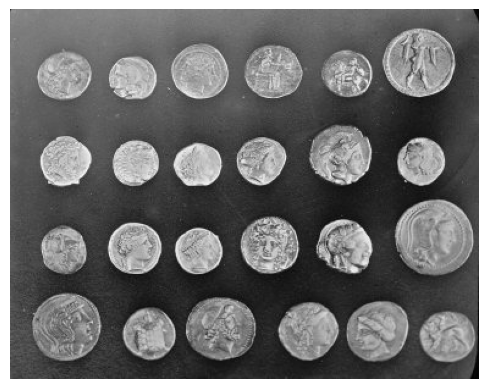

In [2]:
image = data.coins()
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

In [3]:
print("Image shape:", image.shape)

Image shape: (303, 384)


### Task 1

In [4]:
def generate_gaussian_kernel(size=None, sigma=1.0):
    """Construct a normalized 2D Gaussian kernel from first principles.

    The kernel extends to approximately three standard deviations in each
    direction. If a size is supplied, its half-width determines the radius.
    """
    sigma = float(sigma)
    if sigma <= 0:
        raise ValueError("sigma must be positive")

    if size is None:
        radius = max(1, int(np.ceil(3.0 * sigma)))
    else:
        radius = max(1, int(size) // 2)

    coords = np.arange(-radius, radius + 1, dtype=np.float64)
    x, y = np.meshgrid(coords, coords)
    kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
    kernel_sum = kernel.sum()
    if kernel_sum == 0 or not np.isfinite(kernel_sum):
        raise ValueError("Gaussian kernel could not be normalized")
    return kernel / kernel_sum


In [5]:
import scipy.signal as signal

In [6]:
def gaussian_blur(image, sigma):
    """Gaussian smoothing using the manually constructed kernel and convolution."""
    sigma = float(sigma)
    radius = max(1, int(np.ceil(3.0 * sigma)))
    kernel = generate_gaussian_kernel(size=2 * radius + 1, sigma=sigma)
    image_float = np.asarray(image, dtype=np.float64)
    return signal.convolve2d(
        image_float, kernel, mode='same', boundary='symm'
    )


In [7]:
sigmas = [1,2,4,8,16]
scale_space = {}

for sigma in sigmas:
    scale_space[sigma] = gaussian_blur(image, sigma)

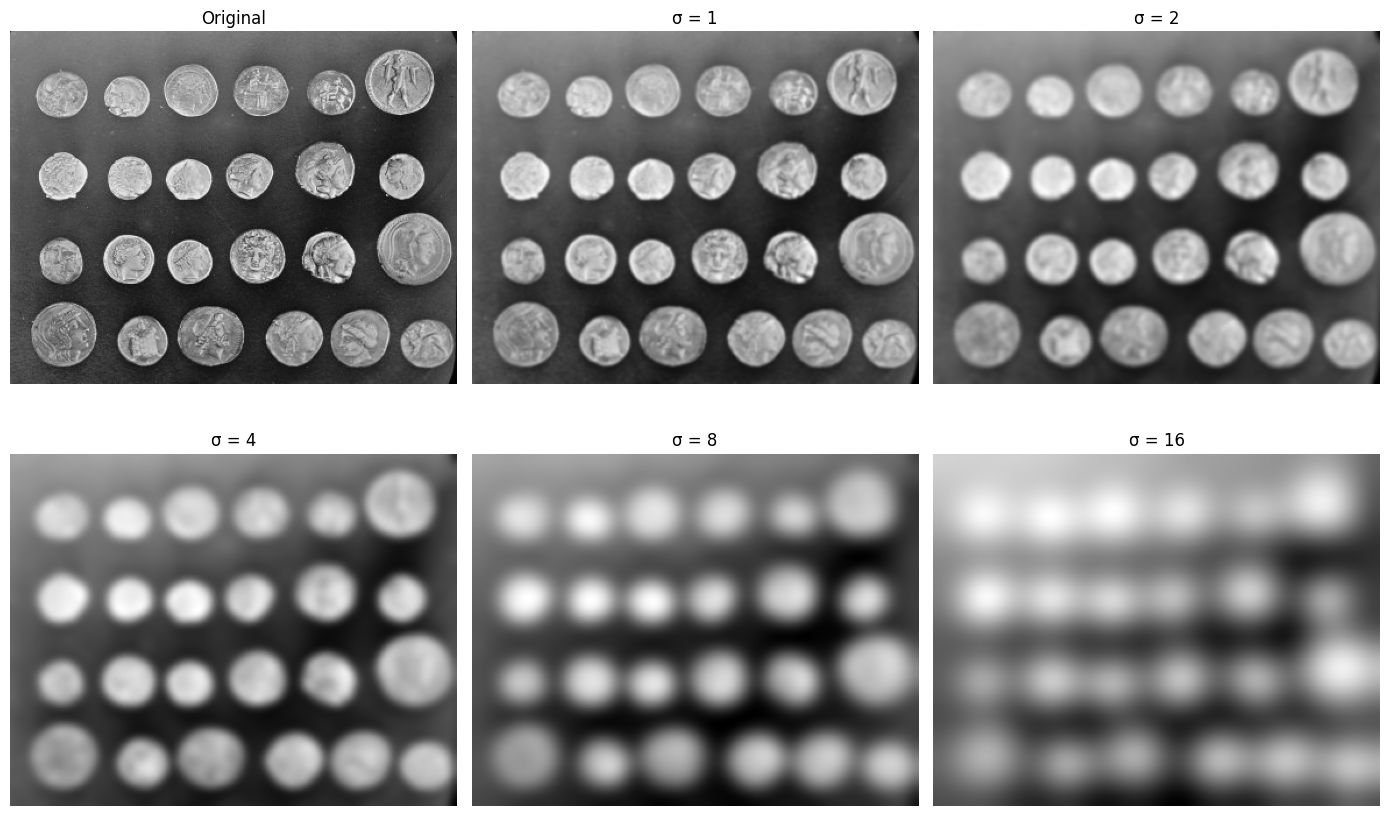

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title("Original")

for ax, sigma in zip(axes.flat[1:], sigmas):
    ax.imshow(scale_space[sigma], cmap='gray')
    ax.set_title(f"σ = {sigma}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Task 1 — Discussion of Gaussian scale space

As σ increases, the Gaussian kernel averages intensities over a wider neighbourhood. At σ = 1, fine texture, small details, and coin boundaries remain relatively sharp. At σ = 2 and σ = 4, high-frequency variation and small details are progressively smoothed, while the larger coin structures remain visible. At σ = 8 and especially σ = 16, small structures and narrow edges become blurred and nearby boundaries may merge. This smoothing suppresses high-frequency noise, but it also removes genuine fine detail. The larger scales therefore emphasize broad structures rather than small ones. These are qualitative observations from the displayed image, not a claim that every edge becomes weaker at exactly the same rate.


### Task 2

In [9]:
def downsample(image):
    return cv.resize(image, (image.shape[1]//2, image.shape[0]//2))

In [10]:
def build_pyramid(image, levels=5, sigma=1):
    pyramid = [image]

    current = image

    for _ in range(levels - 1):
        # Gaussian anti-aliasing
        smoothed = gaussian_blur(current, sigma)

        # Downsample by factor of 2
        current = downsample(smoothed)

        pyramid.append(current)

    return pyramid

In [11]:
pyramid = build_pyramid(image, levels=5, sigma=1)

In [12]:
for i, level in enumerate(pyramid):
    print(f"Level {i}: {level.shape}")

Level 0: (303, 384)
Level 1: (151, 192)
Level 2: (75, 96)
Level 3: (37, 48)
Level 4: (18, 24)


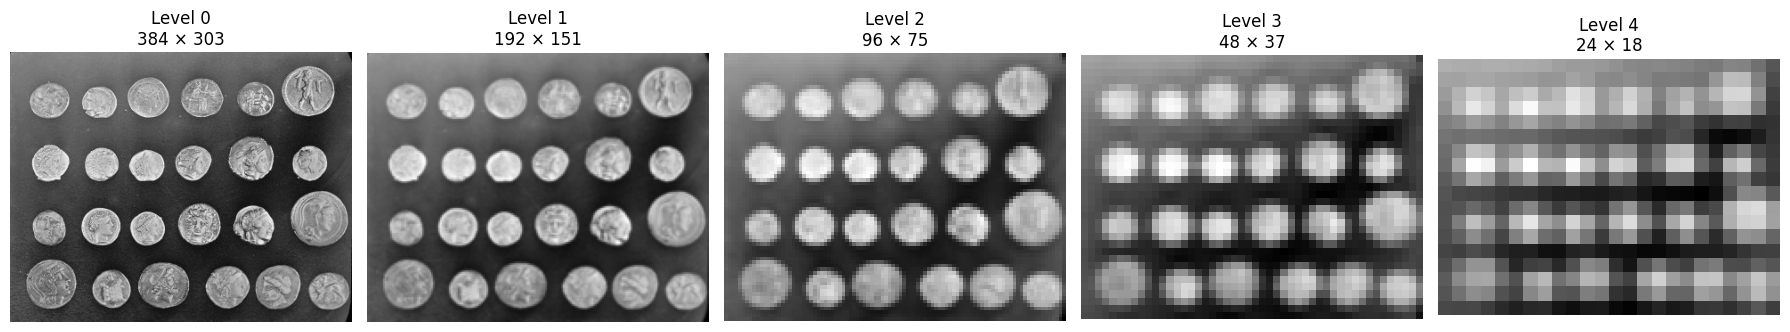

In [13]:
fig, axes = plt.subplots(1, len(pyramid), figsize=(18, 5))

for i, (ax, level) in enumerate(zip(axes, pyramid)):
    ax.imshow(level, cmap='gray')
    ax.set_title(f"Level {i}\n{level.shape[1]} × {level.shape[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### why we do Gaussian smoothing, before downsampling? 
##### Before downsampling the image by a factor of 2, Gaussian smoothing is applied as an anti-aliasing filter. Downsampling reduces the spatial resolution of the image and therefore reduces the maximum spatial frequency that can be represented. High-frequency components that exceed this new limit can produce aliasing, causing false patterns, distortions, or loss of structural information. This produces a smoother and more stable representation at each pyramid level and prevents high-frequency image information from being incorrectly represented as lower-frequency structures.

### Task 3

In [14]:
def laplacian(image):
    kernel_x = np.array([[1, -2, 1]], dtype=np.float64)

    kernel_y = np.array([
        [1],
        [-2],
        [1]
    ], dtype=np.float64)

    d2x = signal.convolve2d(
        image,
        kernel_x,
        mode='same',
        boundary='symm'
    )

    d2y = signal.convolve2d(
        image,
        kernel_y,
        mode='same',
        boundary='symm'
    )

    return d2x + d2y

In [15]:
log_responses = {}

for sigma in sigmas:

    # Gaussian-smoothed image L(x,y,sigma)
    L = scale_space[sigma]

    # Laplacian of L
    lap = laplacian(L)

    # Scale-normalized LoG response
    response = (sigma ** 2) * np.abs(lap)

    log_responses[sigma] = response

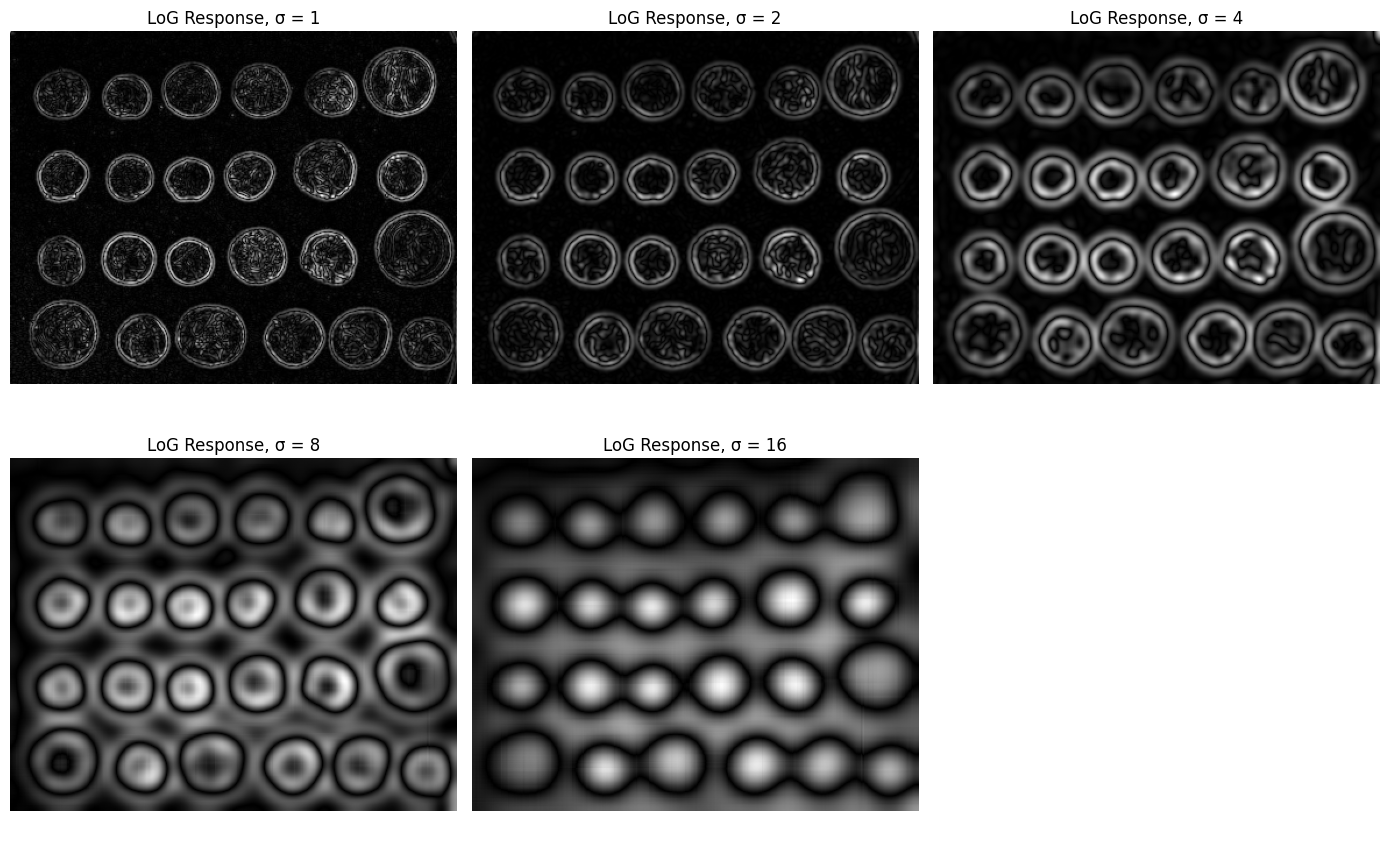

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, sigma in zip(axes.flat, sigmas):

    response = log_responses[sigma]

    ax.imshow(response, cmap='gray')
    ax.set_title(f"LoG Response, σ = {sigma}")
    ax.axis("off")

# Hide unused subplot
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

##### Why use scale normalization?

The magnitude of the Laplacian response changes with the smoothing scale. Multiplying by σ² compensates for this scale dependence and makes responses at different scales more comparable. Under ideal continuous-image and scale-space assumptions, this normalization supports scale-invariant detection: a structure can produce a strong response at its characteristic scale even when its size changes. It does **not** guarantee perfect invariance in a practical implementation. Here, the scale values are discrete, the derivatives are approximated with finite-difference kernels, and resizing, thresholding, and information loss can change the response.


### Task 4

In [17]:
response_volume = np.stack(
    [log_responses[sigma] for sigma in sigmas],
    axis=0
)

print(response_volume.shape)

(5, 303, 384)


In [18]:
def detect_extrema(response_volume, sigmas, threshold):
    """Find strict 3D local maxima by explicitly testing all 26 neighbours.

    The first and last scale slices are skipped because they do not have a
    scale neighbour on both sides. The image border is skipped because a full
    3x3 spatial neighbourhood is not available there.
    """
    response_volume = np.asarray(response_volume, dtype=np.float64)
    num_scales, height, width = response_volume.shape
    if num_scales != len(sigmas):
        raise ValueError("The number of scales must match the volume depth")

    detections = []
    for s in range(1, num_scales - 1):
        current = response_volume[s]
        candidate_y, candidate_x = np.where(current >= threshold)

        for y, x in zip(candidate_y, candidate_x):
            if y == 0 or y == height - 1 or x == 0 or x == width - 1:
                continue

            # A 3x3x3 cube contains the candidate plus its 26 neighbours.
            cube = response_volume[s - 1:s + 2, y - 1:y + 2, x - 1:x + 2]
            neighbours = np.delete(cube.ravel(), 13)  # centre index in 27 values
            value = response_volume[s, y, x]

            # Strict comparison prevents equal-valued plateaus being counted
            # as multiple local maxima.
            if value > neighbours.max():
                detections.append((int(x), int(y), float(sigmas[s]), float(value)))

    return detections


In [19]:
threshold = 0.03 * response_volume.max()

detections = detect_extrema(
    response_volume,
    sigmas,
    threshold
)

print("Number of detected extrema:", len(detections))

Number of detected extrema: 1192


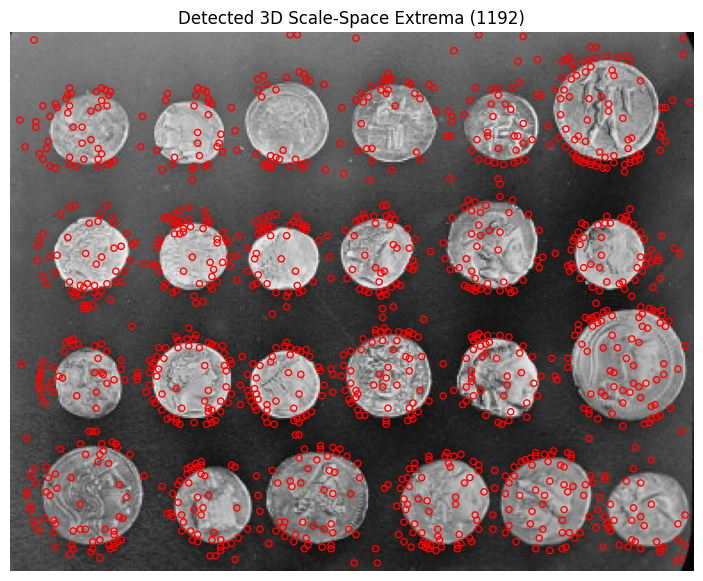

In [20]:
plt.figure(figsize=(10, 7))

plt.imshow(image, cmap='gray')

xs = [d[0] for d in detections]
ys = [d[1] for d in detections]

plt.scatter(
    xs,
    ys,
    s=20,
    facecolors='none',
    edgecolors='red'
)

plt.title(f"Detected 3D Scale-Space Extrema ({len(detections)})")
plt.axis("off")
plt.show()

### Task 5 — Blob radius estimation and visualization

For each detected extremum, the assignment estimates the blob radius as

**r ≈ √2 · σ**

A detection is stored as (x,y,σ,response), so its circle is centred at (x,y) and has radius √2 · σ. To make the plot readable, we apply a simple overlap-based filtering step: stronger detections are kept first, and detections whose centres fall inside an already-kept circle are discarded. This is post-processing, not a built-in blob detector.

**Boundary note:** A 3D extremum must have both a lower and a higher sampled scale, so the first and last scale slices are not eligible. Spatial border pixels are also omitted because a complete 3×3×3 neighbourhood is required. The detector above is the single implementation used by the remaining tasks.


#### Remove heavily overlapping detections

A single coin or textured region can produce nearby maxima at more than one location. The following straightforward filtering keeps the strongest response first and removes detections whose centres are already covered by a stronger detection's estimated radius. This makes the circle plot easier to interpret; it may also remove genuinely nearby blobs, so it is a visualization-oriented heuristic.

In [21]:
def remove_overlapping_detections(detections):
    # Sort from strongest to weakest response.
    ordered = sorted(detections, key=lambda d: d[3], reverse=True)
    kept = []

    for candidate in ordered:
        x, y, sigma, response = candidate
        radius = np.sqrt(2) * sigma
        overlaps = False

        for old in kept:
            ox, oy, osigma, _ = old
            old_radius = np.sqrt(2) * osigma
            distance = np.hypot(x - ox, y - oy)

            # Keep the candidate only if its centre is not covered by
            # a stronger previously accepted detection.
            if distance < max(radius, old_radius):
                overlaps = True
                break

        if not overlaps:
            kept.append(candidate)

    return kept


filtered_detections = remove_overlapping_detections(detections)
print("Detections before overlap filtering:", len(detections))
print("Detections after overlap filtering:", len(filtered_detections))

Detections before overlap filtering: 1192
Detections after overlap filtering: 653


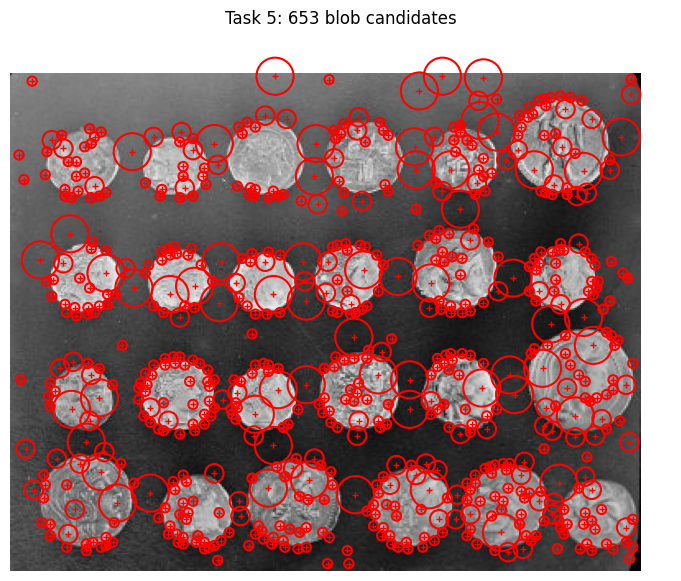

In [22]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image, cmap="gray")

for x, y, sigma, response in filtered_detections:
    radius = np.sqrt(2) * sigma
    circle = plt.Circle((x, y), radius, fill=False,
                        edgecolor="red", linewidth=1.5)
    ax.add_patch(circle)
    ax.plot(x, y, "r+", markersize=4)

ax.set_title(f"Task 5: {len(filtered_detections)} blob candidates")
ax.axis("off")
plt.show()


### Task 6 — Scale invariance analysis

The image is resized using the required factors s ∈ {1.00, 0.75, 0.50, 0.25}, and the detector is run independently on each variant.

Because the resized dimensions are rounded to integers, the actual horizontal and vertical scale ratios are calculated from the resulting image dimensions. Detection centres are mapped back to the original-image coordinate system using these actual ratios. The scale σ is mapped back using the geometric mean of the two ratios.

The mapped detections are compared one-to-one against the detections from the original image, using a spatial matching tolerance of 8 original-image pixels.

This experiment evaluates practical scale consistency rather than perfect theoretical scale invariance. The detector uses the same discrete σ values for every resized image, so these scales represent different relative object sizes after resizing. Reduction in image resolution also removes spatial detail and can change the detected extrema.

The comparison measures agreement with the original detector output, not absolute detection accuracy. The input image does not contain manually annotated ground-truth blob centres.


In [23]:
SCALE_FACTORS = [1.00, 0.75, 0.50, 0.25]
THRESHOLD_FRACTION = 0.03
MATCH_TOLERANCE_ORIGINAL_PX = 8.0


def run_detector(input_image, sigmas, threshold_fraction=THRESHOLD_FRACTION):
    """Run the from-scratch scale-space, LoG, and 3D-extrema pipeline."""
    input_float = np.asarray(input_image, dtype=np.float64)
    smoothed_images = {
        sigma: gaussian_blur(input_float, sigma)
        for sigma in sigmas
    }
    responses = {
        sigma: (sigma ** 2) * np.abs(laplacian(smoothed_images[sigma]))
        for sigma in sigmas
    }
    volume = np.stack([responses[sigma] for sigma in sigmas], axis=0)
    threshold_value = float(threshold_fraction * volume.max())
    raw = detect_extrema(volume, sigmas, threshold_value)
    filtered = remove_overlapping_detections(raw)
    return volume, threshold_value, raw, filtered



def map_detections_to_original(detections, scale_x, scale_y):
    """Map detection centres and scales back to original-image coordinates."""
    if scale_x <= 0 or scale_y <= 0:
        raise ValueError("Scale factors must be positive")

    # Account for the actual resized dimensions, including rounding.
    scale_for_sigma = np.sqrt(scale_x * scale_y)

    return [
        (
            float(x) / scale_x,
            float(y) / scale_y,
            float(sigma) / scale_for_sigma,
            float(response)
        )
        for x, y, sigma, response in detections
    ]



variants = {}
variant_results = {}

for factor in SCALE_FACTORS:
    if factor == 1.0:
        resized = image.copy()
    else:
        resized = cv.resize(
            image, None, fx=factor, fy=factor,
            interpolation=cv.INTER_AREA
        )

    # Actual resize ratios after OpenCV rounds the output dimensions.
    actual_scale_x = resized.shape[1] / image.shape[1]
    actual_scale_y = resized.shape[0] / image.shape[0]

    volume, thr, raw, filtered = run_detector(resized, sigmas)
    variants[factor] = resized
    variant_results[factor] = {
        "volume": volume,
        "threshold": thr,
        "raw": raw,
        "detections": filtered,
        "mapped_detections": map_detections_to_original(
            filtered, actual_scale_x, actual_scale_y
        ),
        "actual_scale_x": actual_scale_x,
        "actual_scale_y": actual_scale_y

    }

    print(
        f"Scale {factor:.2f}: image {resized.shape}, "
        f"{len(filtered)} detections after overlap filtering, "
        f"threshold={thr:.5g}"
    )


def compare_detection_locations(reference, candidate, tolerance_px):
    """One-to-one nearest assignment; only pairs within tolerance are matches."""
    if not reference or not candidate:
        return {
            "matched": 0,
            "reference_count": len(reference),
            "candidate_count": len(candidate),
            "mean_distance": np.nan,
            "distances": []
        }

    ref_xy = np.asarray([(d[0], d[1]) for d in reference], dtype=np.float64)
    cand_xy = np.asarray([(d[0], d[1]) for d in candidate], dtype=np.float64)
    distances = np.linalg.norm(ref_xy[:, None, :] - cand_xy[None, :, :], axis=2)

    # Penalize pairs outside the tolerance so the assignment prioritizes
    # the number of valid matches before minimizing their distances.
    penalty = (min(len(reference), len(candidate)) + 1) * (tolerance_px + 1.0)
    costs = distances.copy()
    costs[distances > tolerance_px] = penalty
    ref_indices, cand_indices = linear_sum_assignment(costs)

    matched_distances = [
        float(distances[i, j])
        for i, j in zip(ref_indices, cand_indices)
        if distances[i, j] <= tolerance_px
    ]
    return {
        "matched": len(matched_distances),
        "reference_count": len(reference),
        "candidate_count": len(candidate),
        "mean_distance": float(np.mean(matched_distances)) if matched_distances else np.nan,
        "distances": matched_distances
    }


reference_detections = variant_results[1.0]["mapped_detections"]
for factor in SCALE_FACTORS:
    stats = compare_detection_locations(
        reference_detections,
        variant_results[factor]["mapped_detections"],
        MATCH_TOLERANCE_ORIGINAL_PX
    )
    ref_n = stats["reference_count"]
    cand_n = stats["candidate_count"]
    stats["recall_percent"] = 100.0 * stats["matched"] / ref_n if ref_n else np.nan
    stats["precision_percent"] = 100.0 * stats["matched"] / cand_n if cand_n else np.nan
    variant_results[factor]["match_stats"] = stats

print()
print(f"Spatial matching tolerance: {MATCH_TOLERANCE_ORIGINAL_PX:.1f} original-image pixels")


Scale 1.00: image (303, 384), 653 detections after overlap filtering, threshold=2.5628
Scale 0.75: image (227, 288), 397 detections after overlap filtering, threshold=2.5082
Scale 0.50: image (152, 192), 143 detections after overlap filtering, threshold=2.4572
Scale 0.25: image (76, 96), 78 detections after overlap filtering, threshold=2.4109

Spatial matching tolerance: 8.0 original-image pixels


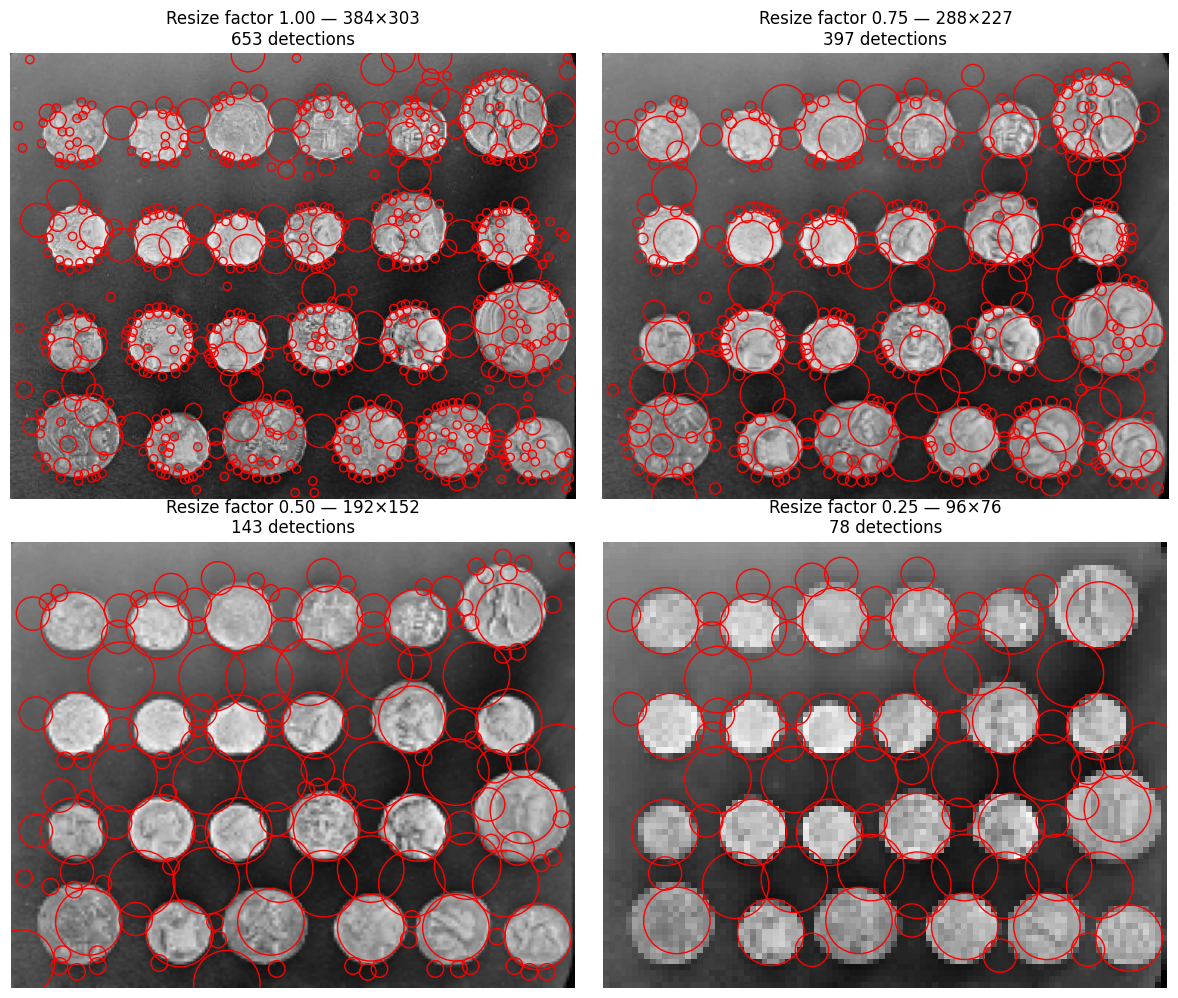

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, factor in zip(axes.flat, SCALE_FACTORS):
    resized = variants[factor]
    found = variant_results[factor]["detections"]
    ax.imshow(resized, cmap="gray")

    for x, y, sigma, response in found:
        radius = np.sqrt(2) * sigma
        ax.add_patch(plt.Circle(
            (x, y), radius, fill=False, edgecolor="red", linewidth=1
        ))

    ax.set_title(
        f"Resize factor {factor:.2f} — {resized.shape[1]}×{resized.shape[0]}\n"
        f"{len(found)} detections"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

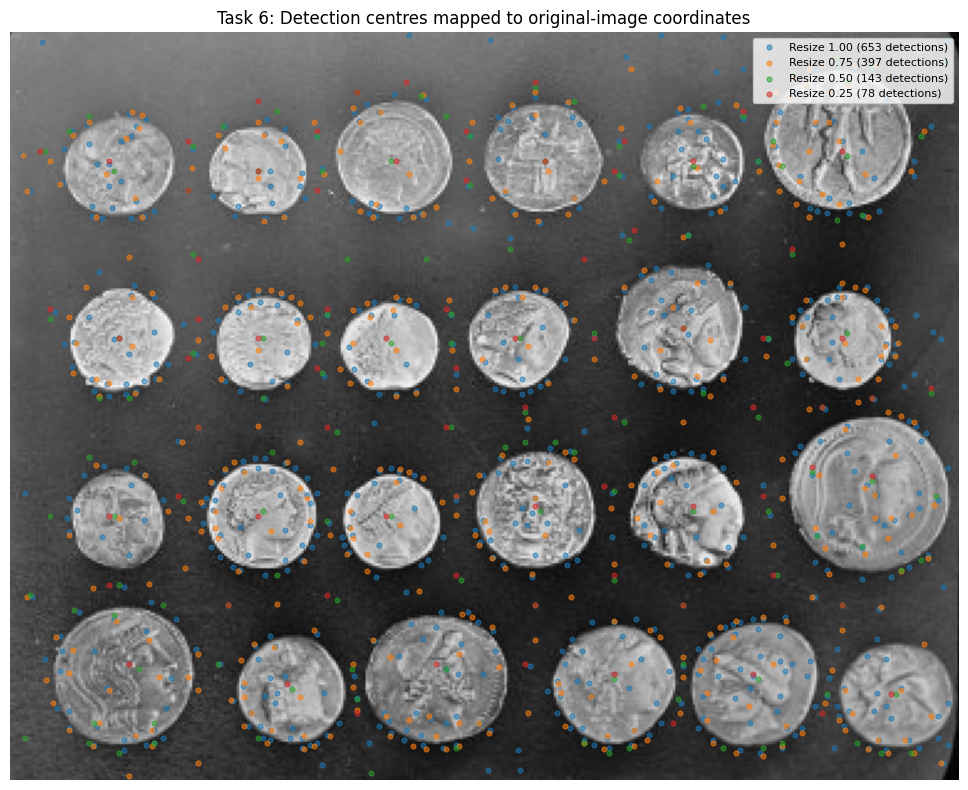

In [25]:
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(image, cmap="gray")
for factor in SCALE_FACTORS:
    mapped = variant_results[factor]["mapped_detections"]
    if mapped:
        ax.scatter(
            [d[0] for d in mapped], [d[1] for d in mapped],
            s=12, alpha=0.55, label=f"Resize {factor:.2f} ({len(mapped)} detections)"
        )
ax.set_title("Task 6: Detection centres mapped to original-image coordinates")
ax.set_xlim(0, image.shape[1] - 1)
ax.set_ylim(image.shape[0] - 1, 0)
ax.legend(loc="upper right", fontsize=8)
ax.axis("off")
plt.tight_layout()
plt.show()


### Task 7 — Quantitative evaluation and parameter discussion

The first table follows the assignment's required columns. The average radius in that table is expressed in the coordinates of each resized image. A second table reports the corresponding average radius after mapping it back to original-image pixels, along with one-to-one spatial agreement against the original-image detections. The comparison uses an 8-pixel tolerance in original-image coordinates; this is an evaluation setting, not the detector's response threshold.


In [26]:
# Required Task 7 summary table.
rows = []
comparison_rows = []
for factor in SCALE_FACTORS:
    result = variant_results[factor]
    found = result["detections"]
    mapped = result["mapped_detections"]

    average_radius_variant = (
        float(np.mean([np.sqrt(2) * d[2] for d in found]))
        if found else np.nan
    )
    average_radius_original = (
        float(np.mean([np.sqrt(2) * d[2] for d in mapped]))
        if mapped else np.nan
    )

    rows.append({
        "Image Variant": "Original" if factor == 1.0 else f"Variant {SCALE_FACTORS.index(factor)}",
        "Resize Factor": factor,
        "Detected Blobs": len(found),
        "Average Radius (r̄, variant px)": average_radius_variant,
        "Detection Threshold": result["threshold"]
    })

    stats = result["match_stats"]
    comparison_rows.append({
        "Resize Factor": factor,
        "Detected Blobs": len(found),
        "Average Radius (original px)": average_radius_original,
        "Matched to Original": stats["matched"],
        "Recall vs Original (%)": stats["recall_percent"],
        "Precision vs Original (%)": stats["precision_percent"],
        "Mean Match Distance (px)": stats["mean_distance"]
    })

results_table = pd.DataFrame(rows)
print("Required Task 7 summary")
display(results_table.round({
    "Resize Factor": 2,
    "Average Radius (r̄, variant px)": 2,
    "Detection Threshold": 5
}))

comparison_table = pd.DataFrame(comparison_rows)
print()
print(f"Cross-resolution comparison (matching tolerance = {MATCH_TOLERANCE_ORIGINAL_PX:.1f} original-image pixels)")
display(comparison_table.round({
    "Resize Factor": 2,
    "Average Radius (original px)": 2,
    "Recall vs Original (%)": 2,
    "Precision vs Original (%)": 2,
    "Mean Match Distance (px)": 2
}))


Required Task 7 summary


,Image Variant,Resize Factor,Detected Blobs,"Average Radius (r̄, variant px)",Detection Threshold
0,Original,1.00,653,4.04,2.56283
1,Variant 1,0.75,397,4.41,2.50818
2,Variant 2,0.50,143,6.21,2.45720
3,Variant 3,0.25,78,4.35,2.41087



Cross-resolution comparison (matching tolerance = 8.0 original-image pixels)


,Resize Factor,Detected Blobs,Average Radius (original px),Matched to Original,Recall vs Original (%),Precision vs Original (%),Mean Match Distance (px)
0,1.00,653,4.04,653,100.00,100.00,0.00
1,0.75,397,5.88,355,54.36,89.42,2.72
2,0.50,143,12.40,108,16.54,75.52,2.64
3,0.25,78,17.38,49,7.50,62.82,3.84


#### Parameter discussion

- **Number of scales / octaves:** The sampled scales are [1,2,4,8,16], which contain five samples and four factor-of-two intervals (octave intervals). They are evaluated at the same image resolution; this is not a Gaussian downsampling pyramid. More samples or a broader scale range can detect a wider range of structures, but use more computation and memory. Because 3D extrema require both a lower and a higher scale, the first and last samples are not eligible as extrema in this implementation.
- **Scale step:** Adjacent values differ by a factor of two. This is computationally convenient but coarse: a blob whose characteristic scale lies between sampled values can have less accurate scale localization. Denser scale sampling can improve this at additional cost.
- **Downsampling factor:** The pyramid uses a factor of two at each step. Gaussian anti-aliasing suppresses frequencies that would otherwise fold into misleading lower-frequency patterns after downsampling. A larger downsampling step is cheaper but discards more spatial information at once.
- **Detection threshold:** The detector uses 3% of the maximum response in each image variant. A higher threshold generally reduces weak responses and false positives but can miss low-contrast structures; a lower threshold increases sensitivity but can admit more texture/noise responses. Because the threshold is relative to each image's maximum, the absolute threshold values may differ between variants.
- **Input resolution:** Lower-resolution images contain less spatial detail. Small coins and fine rim features can disappear, nearby responses may merge, and discretization can shift a detected centre. In addition, the same σ values correspond to different real-world scales after resizing, so using the unchanged scale list is not expected to be perfectly invariant.

#### Interpreting the quantitative comparison

The mapped-coordinate table measures agreement with the original run, not detection precision against annotated ground truth. Its precision and recall labels are therefore relative to the original detector output. The 8-pixel tolerance is explicitly stated and can affect the match counts. The coins image is useful for demonstration because it contains many roughly circular structures, but it is not a controlled benchmark: rims, highlights, texture, and background detail can all create extra responses. Counts should be interpreted as behaviour on this image, not a universal accuracy score.


#### Interpretation of the experimental results

The number of detected blobs decreases from 653 in the original image to 397, 143, and 78 at resize factors of 0.75, 0.50, and 0.25, respectively. The cross-resolution comparison also shows a substantial reduction in recall relative to the original detector as the resolution decreases.

These results indicate that the detector does not consistently retain all detections across resizing operations. Small structures and fine edge details may disappear, nearby responses may merge, and detected centres may shift. Furthermore, the fixed scale list σ ∈ {1, 2, 4, 8, 16} and the response-dependent threshold affect which extrema are retained at each resolution.

The spatial matching statistics measure agreement with the original detector, not ground-truth accuracy. A detection that matches an original detection is spatially consistent within the chosen tolerance, but this alone does not establish that the detected feature is a true semantic blob.



### Bonus — Difference of Gaussians (DoG) approximation

For a modest scale ratio k > 1, the difference between two Gaussian-smoothed images approximates the scale-normalized Laplacian response:

**D(x, y, σ) = [L(x, y, kσ) − L(x, y, σ)] / (k − 1) ≈ σ² ∇²L(x, y, σ)**

The implementation uses k = √2. It compares signed response maps, measures computation time over repeated runs, and compares local-maximum locations at a representative scale. Since this image has no annotated ground-truth blob centres, the location comparison measures agreement between LoG and DoG rather than absolute localization accuracy.


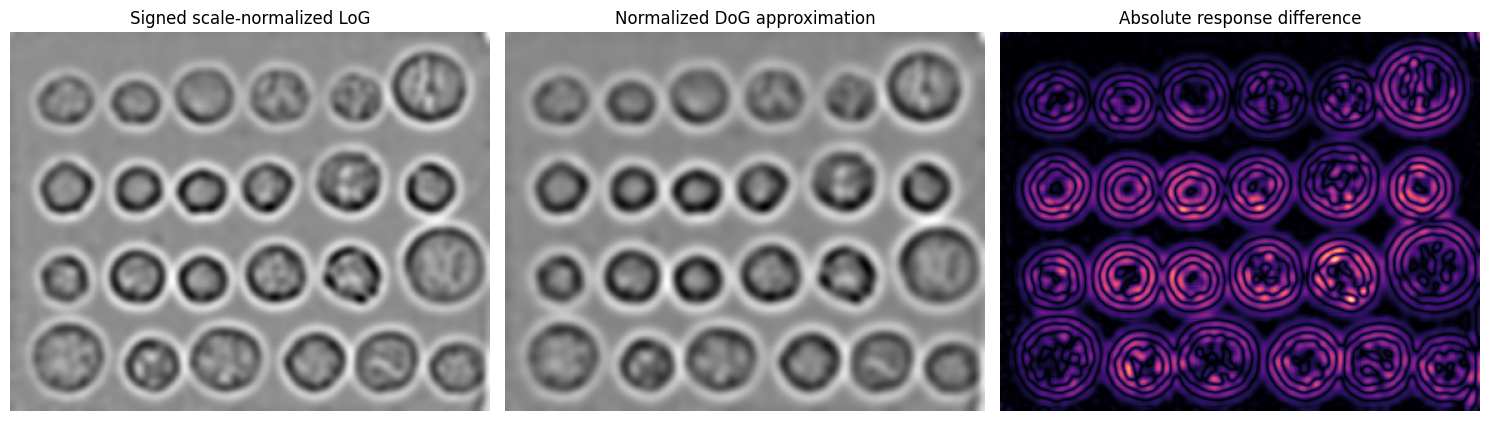

Median LoG computation time (5 runs): 0.13124 s
Median DoG computation time (5 runs): 0.43001 s
Pearson correlation (signed maps): 0.97658
Relative RMS error: 0.22943

LoG local maxima: 728 (threshold=1.9168)
DoG local maxima: 463 (threshold=1.5283)
One-to-one location matches within 5 pixels: 422
LoG maxima matched by DoG: 57.97%
DoG maxima matched by LoG: 91.14%
Mean distance between matched locations: 1.351 px


In [27]:
def dog_response(input_image, sigma, k=np.sqrt(2)):
    """Return the normalized DoG approximation at scale sigma.

    Non-integer sigma values are supported by gaussian_blur().
    """
    input_float = np.asarray(input_image, dtype=np.float64)
    low = gaussian_blur(input_float, sigma)
    high = gaussian_blur(input_float, k * sigma)
    return (high - low) / (k - 1.0)


def median_runtime(function, repeats=5):
    """Return median runtime and final output after one warm-up call."""
    function()  # warm-up
    samples = []
    output = None
    for _ in range(repeats):
        start = time.perf_counter()
        output = function()
        samples.append(time.perf_counter() - start)
    return float(np.median(samples)), output


def detect_2d_local_maxima(response, threshold_fraction=0.03):
    """Find strict 8-neighbourhood maxima without a high-level peak detector."""
    response = np.asarray(response, dtype=np.float64)
    threshold = threshold_fraction * float(response.max())
    candidate_y, candidate_x = np.where(response >= threshold)
    height, width = response.shape
    peaks = []

    for y, x in zip(candidate_y, candidate_x):
        if y == 0 or y == height - 1 or x == 0 or x == width - 1:
            continue
        neighbourhood = response[y - 1:y + 2, x - 1:x + 2].ravel()
        neighbours = np.delete(neighbourhood, 4)
        value = response[y, x]
        if value > neighbours.max():
            peaks.append((int(x), int(y), float(value)))
    return peaks, float(threshold)


def match_peak_locations(reference_peaks, candidate_peaks, tolerance_px=5.0):
    """One-to-one matching of 2D peak coordinates within a spatial tolerance."""
    if not reference_peaks or not candidate_peaks:
        return 0, np.nan, []

    ref_xy = np.asarray([(p[0], p[1]) for p in reference_peaks], dtype=np.float64)
    cand_xy = np.asarray([(p[0], p[1]) for p in candidate_peaks], dtype=np.float64)
    distances = np.linalg.norm(ref_xy[:, None, :] - cand_xy[None, :, :], axis=2)
    penalty = (min(len(reference_peaks), len(candidate_peaks)) + 1) * (tolerance_px + 1.0)
    costs = distances.copy()
    costs[distances > tolerance_px] = penalty
    ref_idx, cand_idx = linear_sum_assignment(costs)
    matched_distances = [
        float(distances[i, j])
        for i, j in zip(ref_idx, cand_idx)
        if distances[i, j] <= tolerance_px
    ]
    mean_distance = float(np.mean(matched_distances)) if matched_distances else np.nan
    return len(matched_distances), mean_distance, matched_distances


comparison_sigma = 4.0

def compute_log_map():
    return (comparison_sigma ** 2) * laplacian(
        gaussian_blur(image.astype(np.float64), comparison_sigma)
    )

def compute_dog_map():
    return dog_response(image, comparison_sigma)

log_seconds, log_map = median_runtime(compute_log_map, repeats=5)
dog_seconds, dog_map = median_runtime(compute_dog_map, repeats=5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(log_map, cmap="gray")
axes[0].set_title("Signed scale-normalized LoG")
axes[1].imshow(dog_map, cmap="gray")
axes[1].set_title("Normalized DoG approximation")
axes[2].imshow(np.abs(log_map - dog_map), cmap="magma")
axes[2].set_title("Absolute response difference")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

pearson_correlation = float(np.corrcoef(log_map.ravel(), dog_map.ravel())[0, 1])
relative_rms_error = float(
    np.sqrt(np.mean((log_map - dog_map) ** 2) /
            (np.mean(log_map ** 2) + 1e-12))
)
print(f"Median LoG computation time (5 runs): {log_seconds:.5f} s")
print(f"Median DoG computation time (5 runs): {dog_seconds:.5f} s")
print(f"Pearson correlation (signed maps): {pearson_correlation:.5f}")
print(f"Relative RMS error: {relative_rms_error:.5f}")

# Compare the locations of 2D maxima at the same representative scale.
# Both methods use the same relative threshold fraction within their own map.
log_peaks, log_peak_threshold = detect_2d_local_maxima(np.abs(log_map), 0.03)
dog_peaks, dog_peak_threshold = detect_2d_local_maxima(np.abs(dog_map), 0.03)
matched_count, mean_peak_distance, matched_distances = match_peak_locations(
    log_peaks, dog_peaks, tolerance_px=5.0
)
log_match_rate = 100.0 * matched_count / len(log_peaks) if log_peaks else np.nan
dog_match_rate = 100.0 * matched_count / len(dog_peaks) if dog_peaks else np.nan
print()
print(f"LoG local maxima: {len(log_peaks)} (threshold={log_peak_threshold:.5g})")
print(f"DoG local maxima: {len(dog_peaks)} (threshold={dog_peak_threshold:.5g})")
print("One-to-one location matches within 5 pixels:", matched_count)
print(f"LoG maxima matched by DoG: {log_match_rate:.2f}%")
print(f"DoG maxima matched by LoG: {dog_match_rate:.2f}%")
print(f"Mean distance between matched locations: {mean_peak_distance:.3f} px")


#### Bonus discussion

The DoG response approximates the normalized LoG response, but it is not identical. For this implementation, the median runtime is measured over five runs after a warm-up; timings still depend on the machine, array sizes, and implementation details. DoG computes two Gaussian blurs and subtracts them, whereas LoG computes one Gaussian blur followed by the discrete Laplacian, so the outcome should be reported from the measurements rather than assuming DoG is always faster. The signed-map correlation and relative RMS error summarize response quality. The one-to-one maxima comparison summarizes feature-location agreement within a 5-pixel tolerance at σ = 4. Because there are no labelled ground-truth centres, neither this agreement nor the response correlation is an absolute accuracy score.


### Final summary

This notebook builds Gaussian scale-space and an image pyramid, computes scale-normalized absolute LoG responses, detects 3D local extrema through explicit neighbourhood comparisons, estimates radii, and visualizes detections without a built-in blob detector. It evaluates all four required resize factors, maps detections back to original-image coordinates for a quantified comparison, reports the required Task 7 table, and includes a DoG comparison with response, runtime, and local-maximum location-agreement metrics. Practical limitations include a coarse five-value scale list, border exclusion for 3D extrema, threshold sensitivity, overlap-filtering heuristics, and the absence of ground-truth blob annotations.
